Samajhna pehle: Hyperparameter woh setting hai jo tum training se pehle tay karte ho (jaise max_depth). Model khud use nahi seekhta. Day 68 mein dekha tha ki bina limit ka tree overfit karta hai. Hyperparameters tree ko “rokne” ke tarike hain:

- max_depth: tree kitna gehra ja sakta hai
- min_samples_leaf: ek leaf mein kam se kam kitne customers hone chahiye (chhote, ratte-hue leaves nahi banenge)
- min_samples_split: kisi node ko todne ke liye kam se kam kitne customers chahiye
- ccp_alpha: tree ko bana kar phir “chhaantna” (pruning). Bada value = zyada pruning
- criterion: split ka naap (gini ya entropy)

Aaj ka rule: Tuning sirf X_train par, CV se. Test set band rahega, Day 70 mein wahi dono models ka final comparison karega.

1. Setup:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, validation_curve, GridSearchCV, cross_validate

X_train = pd.read_csv('../../data/processed/X_train.csv')
y_train = pd.read_csv('../../data/processed/y_train.csv').squeeze()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
CLASS_WEIGHT = 'balanced'       # Day 68 jaisa hi rakho
SCORING = 'f1'                  # churn mein Recall/F1 important hai (Day 56B)

2. max_depth ka curve (sabse zaroori chart):

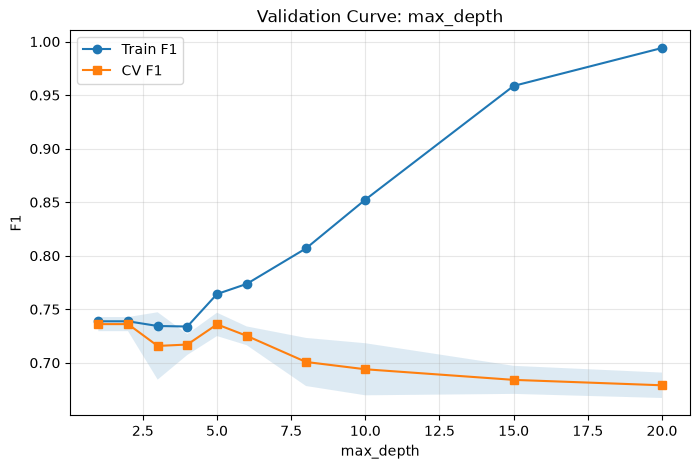

In [2]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]

train_sc, val_sc = validation_curve(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train,
    param_name='max_depth', param_range=depths,
    cv=cv, scoring=SCORING
)

plt.figure(figsize=(8, 5))
plt.plot(depths, train_sc.mean(axis=1), marker='o', label='Train F1')
plt.plot(depths, val_sc.mean(axis=1), marker='s', label='CV F1')
plt.fill_between(depths, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.15)
plt.xlabel('max_depth')
plt.ylabel('F1')
plt.title('Validation Curve: max_depth')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- Underfitting zone (chhota depth): train aur CV dono kam.
- Sweet spot: CV score ka peak.
- Overfitting zone (bada depth): train upar jata hai, CV flat ya neeche. Dono lines ke beech ka gap badhta jata hai.

3. Table version aur “1-standard-error” rule:

In [3]:
curve = pd.DataFrame({
    'max_depth': depths,
    'train_f1': train_sc.mean(axis=1),
    'cv_f1': val_sc.mean(axis=1),
    'cv_std': val_sc.std(axis=1)
}).round(3)
curve['gap'] = (curve['train_f1'] - curve['cv_f1']).round(3)
print(curve)

best = curve.loc[curve['cv_f1'].idxmax()]
threshold = best['cv_f1'] - best['cv_std']
simplest = curve[curve['cv_f1'] >= threshold].sort_values('max_depth').iloc[0]
print(f"\nBest CV F1 at depth {int(best['max_depth'])}: {best['cv_f1']}")
print(f"Simplest depth within 1 std of best: {int(simplest['max_depth'])}")

   max_depth  train_f1  cv_f1  cv_std    gap
0          1     0.739  0.736   0.007  0.003
1          2     0.739  0.736   0.007  0.003
2          3     0.734  0.716   0.031  0.018
3          4     0.734  0.717   0.010  0.017
4          5     0.764  0.736   0.011  0.028
5          6     0.774  0.725   0.009  0.049
6          8     0.807  0.701   0.022  0.106
7         10     0.852  0.694   0.024  0.158
8         15     0.959  0.684   0.013  0.275
9         20     0.994  0.679   0.012  0.315

Best CV F1 at depth 1: 0.736
Simplest depth within 1 std of best: 1


1-std rule: agar ek chhota tree best score se sirf noise jitna peeche hai, to chhota tree chuno. Wo zyada stable hota hai, samajhna aasan hota hai, aur naye data par kam girta hai.

4. min_samples_leaf ka asar (depth ko ek jagah fix karke):

In [4]:
leaf_range = [1, 5, 10, 20, 50, 100, 200]

tr, va = validation_curve(
    DecisionTreeClassifier(max_depth=10, class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train,
    param_name='min_samples_leaf', param_range=leaf_range,
    cv=cv, scoring=SCORING
)
leaf_table = pd.DataFrame({'min_samples_leaf': leaf_range,
                           'train_f1': tr.mean(1), 'cv_f1': va.mean(1)}).round(3)
print(leaf_table)

   min_samples_leaf  train_f1  cv_f1
0                 1     0.852  0.694
1                 5     0.824  0.693
2                10     0.812  0.713
3                20     0.797  0.730
4                50     0.773  0.731
5               100     0.759  0.739
6               200     0.753  0.736


Yeh limit tree ko ek customer ke liye alag leaf banane se rokti hai. Aksar yeh akela max_depth se bhi zyada asardaar hoti hai.

5. Pruning (ccp_alpha):

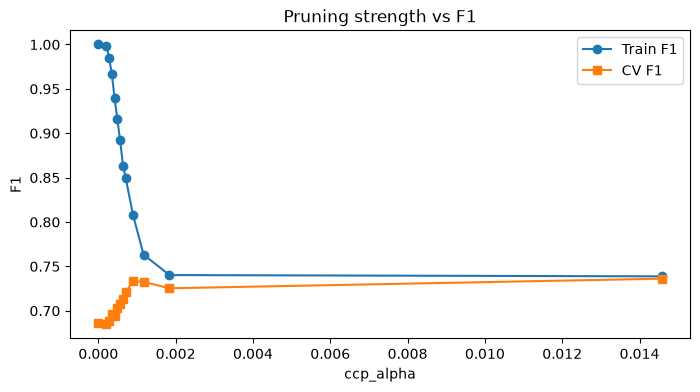

In [5]:
path = DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas, 5))
alphas = alphas[:: max(1, len(alphas) // 12)]        # sirf ~12 values try karo, speed ke liye

tr, va = validation_curve(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train,
    param_name='ccp_alpha', param_range=alphas,
    cv=cv, scoring=SCORING
)
plt.figure(figsize=(8, 4))
plt.plot(alphas, tr.mean(1), marker='o', label='Train F1')
plt.plot(alphas, va.mean(1), marker='s', label='CV F1')
plt.xlabel('ccp_alpha')
plt.ylabel('F1')
plt.title('Pruning strength vs F1')
plt.legend()
plt.show()

6. Sab kuch ek saath: GridSearchCV (preview):

In [6]:
param_grid = {
    'max_depth': [3, 4, 5, 6, 8],
    'min_samples_leaf': [5, 20, 50, 100],
    'min_samples_split': [2, 20, 50],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    param_grid, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=True
)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV F1  : {grid.best_score_:.3f}")

top = (pd.DataFrame(grid.cv_results_)
         .sort_values('rank_test_score')
         [['params', 'mean_train_score', 'mean_test_score', 'std_test_score']]
         .head(8).round(3))
print(top.to_string())

Best params : {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 2}
Best CV F1  : 0.748
                                                                                        params  mean_train_score  mean_test_score  std_test_score
91   {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 20}             0.764            0.748           0.005
90    {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 2}             0.764            0.748           0.005
92   {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 50}             0.764            0.748           0.005
101  {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 20, 'min_samples_split': 50}             0.771            0.745           0.009
103  {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 50, 'min_samples_split': 20}             0.769            0.745           0.014
1

Is grid mein 5 × 4 × 3 × 2 = 120 combinations hain, har ek 5 baar fit hoga (600 fits). Chhote data par yeh seconds mein ho jaata hai. GridSearchCV ka detail Day 84 mein Random Forest/XGBoost ke saath aayega. Aaj bas dekhna hai ki yeh hamare manual loops ka automatic version hai.

Top 8 rows dekhna zaroori hai. Agar kai combinations ka score lagbhag same hai, to sabse simple wala chuno (kam depth, bada min_samples_leaf), sirf rank 1 par mat atko.

7. Search overfit hone ka risk:

In [7]:
print("""
Jitne zyada combinations try karoge, utna chance ki koi ek "lucky" combination CV par accha dikhe.
Isliye CV ka best score thoda optimistic hota hai. Asli, imandaar score sirf test set deta hai,
jise hum ek hi baar (Day 70) kholenge.
""")


Jitne zyada combinations try karoge, utna chance ki koi ek "lucky" combination CV par accha dikhe.
Isliye CV ka best score thoda optimistic hota hai. Asli, imandaar score sirf test set deta hai,
jise hum ek hi baar (Day 70) kholenge.



8. Final tree chuno aur poore X_train par fit karo:

In [8]:
final_params = grid.best_params_          # ya apni pasand ka simple combination yahan likho
final_tree = DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42, **final_params)
final_tree.fit(X_train, y_train)

print("Depth :", final_tree.get_depth())
print("Leaves:", final_tree.get_n_leaves())

res = cross_validate(final_tree, X_train, y_train, cv=cv,
                     scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'], return_train_score=True)
print({k: round(v.mean(), 3) for k, v in res.items() if k.startswith(('test_', 'train_f1'))})

Depth : 5
Leaves: 29
{'test_accuracy': np.float64(0.716), 'test_precision': np.float64(0.752), 'test_recall': np.float64(0.746), 'test_f1': np.float64(0.748), 'train_f1': np.float64(0.764), 'test_roc_auc': np.float64(0.781)}


9. Pehle (Day 68) aur ab ka comparison:

In [9]:
before = cross_validate(DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
                        X_train, y_train, cv=cv, scoring='f1', return_train_score=True)
print(f"Unrestricted tree -> train F1 {before['train_score'].mean():.3f} | CV F1 {before['test_score'].mean():.3f}")
print(f"Tuned tree        -> train F1 {res['train_f1'].mean():.3f} | CV F1 {res['test_f1'].mean():.3f}")

Unrestricted tree -> train F1 1.000 | CV F1 0.686
Tuned tree        -> train F1 0.764 | CV F1 0.748


Tuning ka asli fayda aksar yeh hota hai ki gap kam ho jata hai aur CV score thoda behtar ya barabar rehta hai.

10. Tuned tree save karo (Day 70 ke liye):

In [10]:
import joblib, os
os.makedirs('models', exist_ok=True)
joblib.dump(final_tree, 'models/decision_tree_tuned.joblib')

['models/decision_tree_tuned.joblib']

practice questions

1. SCORING ko 'recall' ya 'roc_auc' karke grid dobara chalao. Best parameters badalte hain? Apne shabdon mein likho ki scoring metric ka chunav tuning ko kaise badalta hai.

2. criterion ke gini aur entropy ke CV scores compare karo. Kya fark itna bada hai ki matter kare?